In [127]:
from torch.utils.data import Dataset , DataLoader
import numpy as np
from typing import Dict , List , Optional
import torch
import torch.nn as nn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors


## Classification Head

In [128]:
class MultiTaskMusicClassifier(nn.Module):
    """
    Modèle de classification multi-tâches avec extraction d'embeddings
    """
    
    def __init__(self, input_dim: int, hidden_dims: List[int], 
                 num_genres: int, num_instruments: int, num_emotions: int,
                 dropout: float = 0.3):
        super().__init__()
        
        # Encodeur partagé
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = hidden_dim
        
        self.encoder = nn.Sequential(*layers)
        self.embedding_dim = hidden_dims[-1]
        
        # Têtes de classification
        self.genre_head = nn.Linear(self.embedding_dim, num_genres)
        self.instrument_head = nn.Linear(self.embedding_dim, num_instruments)
        self.emotion_head = nn.Linear(self.embedding_dim, num_emotions)

    def forward(self, x, return_embeddings=False , genre = False, instrument = False, emotion = False):
        # Extraction des embeddings
        embeddings = self.encoder(x)
        
        if return_embeddings:
            return embeddings
        
        logits = {}
        # Prédictions
        if genre :
            genre_logits = self.genre_head(embeddings)
            logits['genre'] = genre_logits
        if instrument:
            instrument_logits = self.instrument_head(embeddings)
            logits['instrument'] = instrument_logits
        if emotion:
            emotion_logits = self.emotion_head(embeddings)
            logits['emotion'] = emotion_logits
        if not logits :
            raise ValueError("At least one of genre, instrument, or emotion must be True.")

        return logits
    
    def get_embeddings(self, x):
        """Extrait uniquement les embeddings de la dernière couche cachée"""
        with torch.no_grad():
            return self.encoder(x)

## Train Class :

In [129]:
class MusicTrainer:
    """Entraîneur pour le modèle multi-tâches avec visualisation"""
    
    def __init__(self, model, 
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        
        # Historique pour le plotting
        self.history = {
            'train_loss': [],
            'test_loss': [],
            'train_acc': {'genre': [], 'instrument': [], 'emotion': []},
            'test_acc': {'genre': [], 'instrument': [], 'emotion': []}
        }
        
    def train_epoch(self, dataloader: DataLoader, optimizer, task_weights: Dict[str, float] = None,
                    genre=False, instrument=False, emotion=False):
        if task_weights is None:
            task_weights = {'genre': 0.3*(genre == True), 
                          'instrument': 0.3*(instrument==True), 
                          'emotion': 0.3*(emotion==True)}
        
        self.model.train()
        total_loss = 0
        losses = {'genre': 0, 'instrument': 0, 'emotion': 0}
        correct = {'genre': 0, 'instrument': 0, 'emotion': 0}
        total = 0
        
        for batch in dataloader:
            embeddings = batch['embedding'].to(self.device)
            loss_genre, loss_instrument, loss_emotion = 0, 0, 0
            
            # Forward pass
            outputs = self.model(embeddings, genre=genre, instrument=instrument, emotion=emotion)
            
            # Calcul des pertes
            if genre:
                loss_genre = F.cross_entropy(outputs['genre'], batch['genre'].to(self.device))
            
            if instrument:
                loss_instrument = F.cross_entropy(outputs['instrument'], 
                                                  batch['instrument'].to(self.device))
            
            if emotion:
                loss_emotion = F.cross_entropy(outputs['emotion'], batch['emotion'].to(self.device))
            
            # Perte totale pondérée
            loss = (task_weights['genre'] * loss_genre + 
                   task_weights['instrument'] * loss_instrument + 
                   task_weights['emotion'] * loss_emotion)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            # Accumulation des pertes
            total_loss += loss.item()
            if genre:
                losses['genre'] += loss_genre.item()
                preds = outputs['genre'].argmax(dim=1)
                correct['genre'] += (preds == batch['genre'].to(self.device)).sum().item()
            if instrument:
                losses['instrument'] += loss_instrument.item()
                preds = outputs['instrument'].argmax(dim=1)
                correct['instrument'] += (preds == batch['instrument'].to(self.device)).sum().item()
            if emotion:
                losses['emotion'] += loss_emotion.item()
                preds = outputs['emotion'].argmax(dim=1)
                correct['emotion'] += (preds == batch['emotion'].to(self.device)).sum().item()
            
            total += len(embeddings)
        
        n_batches = len(dataloader)
        
        # Calcul des accuracies
        train_acc = {}
        if genre:
            train_acc['genre'] = correct['genre'] / total
        if instrument:
            train_acc['instrument'] = correct['instrument'] / total
        if emotion:
            train_acc['emotion'] = correct['emotion'] / total
        
        # Sauvegarder dans l'historique
        self.history['train_loss'].append(total_loss / n_batches)
        for task in ['genre', 'instrument', 'emotion']:
            if task in train_acc:
                self.history['train_acc'][task].append(train_acc[task])
        
        return {
            'total': total_loss / n_batches,
            'genre': losses['genre'] / n_batches,
            'instrument': losses['instrument'] / n_batches,
            'emotion': losses['emotion'] / n_batches,
            'accuracy': train_acc
        }
    
    def evaluate(self, dataloader: DataLoader, genre=False, emotion=False, instrument=False):
        self.model.eval()
        correct = {'genre': 0, 'instrument': 0, 'emotion': 0}
        total = 0
        total_loss = 0
        
        tasks = []
        if genre:
            tasks.append("genre")
        if emotion:
            tasks.append("emotion")
        if instrument:
            tasks.append("instrument")
        
        task_weights = {'genre': 0.3*(genre == True), 
                       'instrument': 0.3*(instrument==True), 
                       'emotion': 0.3*(emotion==True)}
        
        with torch.no_grad():
            for batch in dataloader:
                embeddings = batch['embedding'].to(self.device)
                outputs = self.model(embeddings, genre=genre, emotion=emotion, instrument=instrument)
                
                # Calcul de la perte
                loss_genre, loss_instrument, loss_emotion = 0, 0, 0
                if genre:
                    loss_genre = F.cross_entropy(outputs['genre'], batch['genre'].to(self.device))
                if instrument:
                    loss_instrument = F.cross_entropy(outputs['instrument'], 
                                                      batch['instrument'].to(self.device))
                if emotion:
                    loss_emotion = F.cross_entropy(outputs['emotion'], batch['emotion'].to(self.device))
                
                loss = (task_weights['genre'] * loss_genre + 
                       task_weights['instrument'] * loss_instrument + 
                       task_weights['emotion'] * loss_emotion)
                total_loss += loss.item()
                
                for task in tasks:
                    preds = outputs[task].argmax(dim=1)
                    correct[task] += (preds == batch[task].to(self.device)).sum().item()
                
                total += len(embeddings)
        
        test_acc = {task: correct[task] / total for task in tasks}
        test_loss = total_loss / len(dataloader)
        
        # Sauvegarder dans l'historique
        self.history['test_loss'].append(test_loss)
        for task in tasks:
            self.history['test_acc'][task].append(test_acc[task])
        
        return test_acc
    
    def plot_metrics(self, figsize=(15, 10), save_path=None):
        """Affiche les courbes de loss et accuracy pour train/test"""
        # Déterminer quelles tâches ont été entraînées
        active_tasks = []
        if len(self.history['train_acc']['genre']) > 0:
            active_tasks.append('genre')
        if len(self.history['train_acc']['instrument']) > 0:
            active_tasks.append('instrument')
        if len(self.history['train_acc']['emotion']) > 0:
            active_tasks.append('emotion')
        
        num_plots = 1 + len(active_tasks)  # 1 pour loss + 1 par tâche
        
        # Calculer la disposition des subplots
        if num_plots == 1:
            nrows, ncols = 1, 1
        elif num_plots == 2:
            nrows, ncols = 1, 2
        elif num_plots == 3:
            nrows, ncols = 2, 2
        else:
            nrows, ncols = 2, 2
        
        fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
        if num_plots == 1:
            axes = [axes]
        else:
            axes = axes.flatten()
        
        epochs = range(1, len(self.history['train_loss']) + 1)
        
        # Plot 1: Loss Total
        axes[0].plot(epochs, self.history['train_loss'], 'b-', label='Train Loss', linewidth=2)
        axes[0].plot(epochs, self.history['test_loss'], 'r-', label='Test Loss', linewidth=2)
        axes[0].set_xlabel('Epoch', fontsize=12)
        axes[0].set_ylabel('Loss', fontsize=12)
        axes[0].set_title('Training vs Test Loss', fontsize=14, fontweight='bold')
        axes[0].legend(fontsize=10)
        axes[0].grid(True, alpha=0.3)
        
        # Plots pour chaque tâche active
        task_titles = {
            'genre': 'Genre Classification Accuracy',
            'instrument': 'Instrument Classification Accuracy',
            'emotion': 'Emotion Classification Accuracy'
        }
        
        for idx, task in enumerate(active_tasks, start=1):
            # Créer des epochs spécifiques pour chaque tâche
            task_epochs = range(1, len(self.history['train_acc'][task]) + 1)
            
            axes[idx].plot(task_epochs, self.history['train_acc'][task], 'b-', 
                          label='Train Acc', linewidth=2)
            axes[idx].plot(task_epochs, self.history['test_acc'][task], 'r-', 
                          label='Test Acc', linewidth=2)
            axes[idx].set_xlabel('Epoch', fontsize=12)
            axes[idx].set_ylabel('Accuracy', fontsize=12)
            axes[idx].set_title(task_titles[task], fontsize=14, fontweight='bold')
            axes[idx].legend(fontsize=10)
            axes[idx].grid(True, alpha=0.3)
        
        # Cacher les axes non utilisés
        for idx in range(num_plots, len(axes)):
            axes[idx].set_visible(False)
        
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Plot saved to {save_path}")
        
        plt.show()
    
    def plot_combined_accuracy(self, figsize=(12, 6), save_path=None):
        """Affiche toutes les accuracies actives sur un seul graphique"""
        # Déterminer quelles tâches ont été entraînées
        active_tasks = []
        if len(self.history['train_acc']['genre']) > 0:
            active_tasks.append('genre')
        if len(self.history['train_acc']['instrument']) > 0:
            active_tasks.append('instrument')
        if len(self.history['train_acc']['emotion']) > 0:
            active_tasks.append('emotion')
        
        if not active_tasks:
            print("No tasks have been trained yet.")
            return
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
        
        colors = {'genre': 'b', 'instrument': 'g', 'emotion': 'r'}
        markers = {'genre': 'o', 'instrument': 's', 'emotion': '^'}
        
        # Train accuracies
        for task in active_tasks:
            task_epochs = range(1, len(self.history['train_acc'][task]) + 1)
            ax1.plot(task_epochs, self.history['train_acc'][task], 
                    f'{colors[task]}-', label=task.capitalize(), 
                    linewidth=2, marker=markers[task], markersize=4)
        ax1.set_xlabel('Epoch', fontsize=12)
        ax1.set_ylabel('Accuracy', fontsize=12)
        ax1.set_title('Train Accuracy - Active Tasks', fontsize=14, fontweight='bold')
        ax1.legend(fontsize=10)
        ax1.grid(True, alpha=0.3)
        
        # Test accuracies
        for task in active_tasks:
            task_epochs = range(1, len(self.history['test_acc'][task]) + 1)
            ax2.plot(task_epochs, self.history['test_acc'][task], 
                    f'{colors[task]}-', label=task.capitalize(), 
                    linewidth=2, marker=markers[task], markersize=4)
        ax2.set_xlabel('Epoch', fontsize=12)
        ax2.set_ylabel('Accuracy', fontsize=12)
        ax2.set_title('Test Accuracy - Active Tasks', fontsize=14, fontweight='bold')
        ax2.legend(fontsize=10)
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Plot saved to {save_path}")
        
        plt.show()




## Prepare Data

In [130]:
# Fonction principale d'utilisation
def prepare_data(csv_path: str , tasks = []):
    """
    Prépare les données à partir du CSV
    """
    data = pd.read_csv(csv_path)

    print(f"Premières lignes:\n{data.head()}")
    
    
    print("Recherche des colonnes d'embeddings...")
    # Identifier les colonnes numériques qui ne sont pas des labels
    exclude_cols = ['genre', 'instrument', 'emotion', 'track_id', 'Unnamed: 0','filename']
    embedding_columns = [col for col in data.columns 
                       if col not in exclude_cols]
    
    if not embedding_columns:
        raise ValueError("Aucune colonne d'embedding trouvée. "
                       "Spécifiez le nom de la colonne avec embedding_column=")
    
    print(f"Colonnes d'embeddings détectées: {len(embedding_columns)} colonnes")
    
    # Extraire et convertir
    embeddings = data[embedding_columns].values
    
    # Gérer les types non-numériques
    if embeddings.dtype == object:
        # Convertir chaque cellule en float
        embeddings_list = []
        for row in embeddings:
            parsed_row = []
            for val in row:
                try:
                    parsed_row.append(float(val))
                except (ValueError, TypeError):
                    # Valeur manquante ou invalide
                    parsed_row.append(0.0)
            embeddings_list.append(parsed_row)
        embeddings = np.array(embeddings_list, dtype=np.float32)
    else:
        embeddings = embeddings.astype(np.float32)
    
    print(f"Shape des embeddings: {embeddings.shape}")
    print(f"Dtype: {embeddings.dtype}")
    
    # Encoder les labels
    label_encoders = {}
    labels = {}
    
    for task in tasks:
        le = LabelEncoder()
        labels[task] = le.fit_transform(data[task].values)
        label_encoders[task] = le
    
    # Split train/test
    indices = np.arange(len(embeddings))
    train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42)
    
    train_embeddings = embeddings[train_idx]
    test_embeddings = embeddings[test_idx]
    train_labels = {k: v[train_idx] for k, v in labels.items()}
    test_labels = {k: v[test_idx] for k, v in labels.items()}
    
    # Récupérer les track IDs si disponibles
    filenames = data['filename'].values if 'filename' in data.columns else None
    
    num_classes = {}
    for tak in tasks :
        num_classes[task] = len(label_encoders[task].classes_)
    
    return {
        'train': (train_embeddings, train_labels),
        'test': (test_embeddings, test_labels),
        'label_encoders': label_encoders,
        'filenames_test': filenames[test_idx] if filenames is not None else None,
        'filenames_train': filenames[train_idx] if filenames is not None else None,
        'num_classes':num_classes
    }


In [131]:
class MusicDataset(Dataset):
    """Dataset pour les embeddings musicaux avec labels multiclasses"""
    
    def __init__(self, embeddings: np.ndarray, labels: Dict[str, np.ndarray ],genre = False
                 , emotion = False , instrument = False):
        self.embeddings = torch.FloatTensor(embeddings)
        self.labels = {key: torch.LongTensor(val) for key, val in labels.items()}
        self.emotion = emotion
        self.genre = genre
        self.instrument = instrument
        
        
    def __len__(self):
        return len(self.embeddings)
    
    def __getitem__(self, idx ):
        item = {}
        item["embedding"]= self.embeddings[idx]
        
        if self.genre :
            item["genre"] = self.labels['genre'][idx]
        if self.instrument :
            item["instrument"] = self.labels["instrument"][idx]
        if self.emotion :
            item["emotion"] = self.labels["emotion"][idx]
        
        return item


## Genre DataLoader

In [132]:
genre_csv_path = "../embeddings/muq_embedding_jamendo_genre.csv"

genre_data_dict = prepare_data(genre_csv_path ,["genre"])

# Charger aussi le DataFrame complet pour les infos
genre_full_data = pd.read_csv(genre_csv_path)

# 2. Créer les datasets et dataloaders
genre_train_dataset = MusicDataset(*genre_data_dict['train'] , genre= True)
genre_test_dataset = MusicDataset(*genre_data_dict['test'] , genre = True)    
genre_train_loader = DataLoader(genre_train_dataset, batch_size=32, shuffle=True)
genre_test_loader = DataLoader(genre_test_dataset, batch_size=32)
genre_file_names_test = genre_data_dict['filenames_test']
print(len(genre_file_names_test))

Premières lignes:
          0         1         2         3         4         5         6  \
0 -0.587135  0.079160  0.353691  0.245319  0.082533 -0.010441  0.357227   
1 -0.751088  0.097931  0.253102  0.188653  0.124648 -0.017334  0.463529   
2 -0.261534  0.036251  0.177986  0.166797  0.049368  0.272909  0.204142   
3  0.040156  0.055310  0.118390  0.016677  0.058096  0.045813  0.083365   
4  0.136029  0.305014 -0.079031  0.289113  0.093749  0.040490  0.150780   

          7         8         9  ...      1016      1017      1018      1019  \
0 -0.170238 -0.066047 -0.058677  ...  0.199485  0.069904 -0.023042 -0.196375   
1 -0.222426  0.328852 -0.284341  ... -0.278078 -0.515481 -0.083564 -0.507680   
2 -0.225154 -0.040714  0.009009  ...  0.314144 -0.273302  0.004630  0.352864   
3  0.062885 -0.283016 -0.142441  ...  0.211610  0.074363 -0.074781  0.307205   
4 -0.199864 -0.336270 -0.348051  ... -0.109612 -0.357117  0.004530  0.333002   

       1020      1021      1022      1023        f

## Emotions Dataloader

In [133]:
emotion_csv_path = "../embeddings/muq_embedding_jamendo_emotion.csv"

emotion_data_dict = prepare_data(emotion_csv_path ,["emotion"])

# Charger aussi le DataFrame complet pour les infos
emotion_full_data = pd.read_csv(emotion_csv_path)

# 2. Créer les datasets et dataloaders
emotion_train_dataset = MusicDataset(*emotion_data_dict['train'] , emotion= True)
emotion_test_dataset = MusicDataset(*emotion_data_dict['test'] , emotion= True)

emotion_train_loader = DataLoader(emotion_train_dataset, batch_size=32, shuffle=True)
emotion_test_loader = DataLoader(emotion_test_dataset, batch_size=32)
emotion_file_names_test = emotion_data_dict['filenames_test']
print(len(emotion_file_names_test))

Premières lignes:
          0         1         2         3         4         5         6  \
0 -1.014330  0.299867 -0.026429 -0.034907  0.105002 -0.166565  0.185746   
1 -0.296392  0.094969  0.318233 -0.131164  0.243839 -0.156306  0.208215   
2 -0.533128  0.220536  0.049518 -0.122488  0.155495 -0.035372 -0.045436   
3  0.028921  0.034335  0.226698  0.307516  0.108670 -0.016680  0.082826   
4 -0.049983 -0.007301  0.369498  0.064631 -0.036221  0.049407  0.067547   

          7         8         9  ...      1016      1017      1018      1019  \
0 -0.025189 -0.198996 -0.043627  ...  0.064802 -0.210932 -0.047076 -0.085614   
1  0.051960 -0.299031 -0.337661  ...  0.090584 -0.271801 -0.060468 -0.173556   
2 -0.207098 -0.328057 -0.052976  ...  0.125660 -0.029893  0.058449 -0.040062   
3 -0.022572  0.061662 -0.311387  ...  0.333726 -0.190573 -0.035553 -0.275131   
4 -0.369580 -0.188362 -0.428403  ... -0.051085 -0.299568 -0.032068 -0.134711   

       1020      1021      1022      1023         

## Instrument DataLoader

In [134]:
instrument_csv_path = "../embeddings/muq_embedding_jamendo_instrument.csv"

instrument_data_dict = prepare_data(instrument_csv_path ,["instrument"])

# Charger aussi le DataFrame complet pour les infos
instrument_full_data = pd.read_csv(instrument_csv_path)

# 2. Créer les datasets et dataloaders
instrument_train_dataset = MusicDataset(*instrument_data_dict['train'] , instrument= True)
instrument_test_dataset = MusicDataset(*instrument_data_dict['test'] , instrument= True)

instrument_train_loader = DataLoader(instrument_train_dataset, batch_size=32, shuffle=True)
instrument_test_loader = DataLoader(instrument_test_dataset, batch_size=32)
instrument_file_names_test = instrument_data_dict['filenames_test']
print(len(instrument_file_names_test))

Premières lignes:
          0         1         2         3         4         5         6  \
0 -0.146160  0.013999  0.433724  0.193177  0.370009 -0.030213  0.466128   
1  0.023737 -0.300842  0.006912  0.068131 -0.036366 -0.033135  0.166256   
2 -0.604804 -0.144246  0.355515  0.171825 -0.043106  0.062507  0.334240   
3 -0.361923  0.128809  0.277128  0.244612 -0.004795  0.048914  0.440680   
4  0.006920  0.146706  0.184989 -0.162900  0.042404  0.116230 -0.124767   

          7         8         9  ...      1016      1017      1018      1019  \
0 -0.373466 -0.131159 -0.469908  ...  0.142568 -0.160451 -0.029653 -0.161095   
1  0.098332  0.145234  0.152011  ... -0.008720 -0.112146 -0.043446 -0.417570   
2 -0.084645  0.324922 -0.388634  ...  0.032688 -0.238653 -0.052104 -0.810456   
3 -0.177926  0.380534 -0.193872  ... -0.037671 -0.285094 -0.056580 -0.725003   
4  0.030061  0.106874 -0.057926  ...  0.230681 -0.514667 -0.164252  0.227609   

       1020      1021      1022      1023        f

# Initialise the model and train it 

In [135]:
# Initialiser le modèle
input_dim = instrument_data_dict['train'][0].shape[1]

model = MultiTaskMusicClassifier(
    input_dim=input_dim,
    hidden_dims=[512, 256, 128],
    num_genres=genre_data_dict['num_classes']['genre'],
    num_instruments=instrument_data_dict['num_classes']['instrument'],
    num_emotions=emotion_data_dict['num_classes']['emotion']
)

In [136]:
# Entraîner le modèle
trainer = MusicTrainer(model)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Entraînement du modèle sur la tache emotion")
for epoch in range(50):
    
    #Train emotion 
    emotion_train_losses = trainer.train_epoch(emotion_train_loader, optimizer , emotion= True)
    emotion_test_acc = trainer.evaluate(emotion_test_loader, emotion=True)
    
    #Train genre 
    genre_train_losses = trainer.train_epoch(genre_train_loader, optimizer , genre= True)
    genre_test_acc = trainer.evaluate(genre_test_loader, genre=True)
    
    #Train instrument 
    instrument_train_losses = trainer.train_epoch(instrument_train_loader, optimizer , instrument= True)
    instrument_test_acc = trainer.evaluate(instrument_test_loader, instrument=True)   
    
    print("=" * 50)
    print(f"Epoch [{epoch+1:02d}/50]")
    print("-" * 50)

    print(f" Emotion")
    print(f"   • Train Loss : {emotion_train_losses['total']:.4f}")
    print(f"   • Test Acc   : {emotion_test_acc['emotion']:.3f}")

    print(f" Genre")
    print(f"   • Train Loss : {genre_train_losses['total']:.4f}")
    print(f"   • Test Acc   : {genre_test_acc['genre']:.3f}")

    print(f" Instrument")
    print(f"   • Train Loss : {instrument_train_losses['total']:.4f}")
    print(f"   • Test Acc   : {instrument_test_acc['instrument']:.3f}")

    print()

Entraînement du modèle sur la tache emotion
Epoch [01/50]
--------------------------------------------------
 Emotion
   • Train Loss : 0.4172
   • Test Acc   : 0.525
 Genre
   • Train Loss : 0.7115
   • Test Acc   : 0.466
 Instrument
   • Train Loss : 0.5805
   • Test Acc   : 0.388

Epoch [02/50]
--------------------------------------------------
 Emotion
   • Train Loss : 0.3727
   • Test Acc   : 0.557
 Genre
   • Train Loss : 0.5428
   • Test Acc   : 0.559
 Instrument
   • Train Loss : 0.4915
   • Test Acc   : 0.485

Epoch [03/50]
--------------------------------------------------
 Emotion
   • Train Loss : 0.3446
   • Test Acc   : 0.606
 Genre
   • Train Loss : 0.4628
   • Test Acc   : 0.577
 Instrument
   • Train Loss : 0.4547
   • Test Acc   : 0.515

Epoch [04/50]
--------------------------------------------------
 Emotion
   • Train Loss : 0.3182
   • Test Acc   : 0.628
 Genre
   • Train Loss : 0.4080
   • Test Acc   : 0.590
 Instrument
   • Train Loss : 0.4232
   • Test Acc   :

Plot saved to ../fig/training_metrics.png


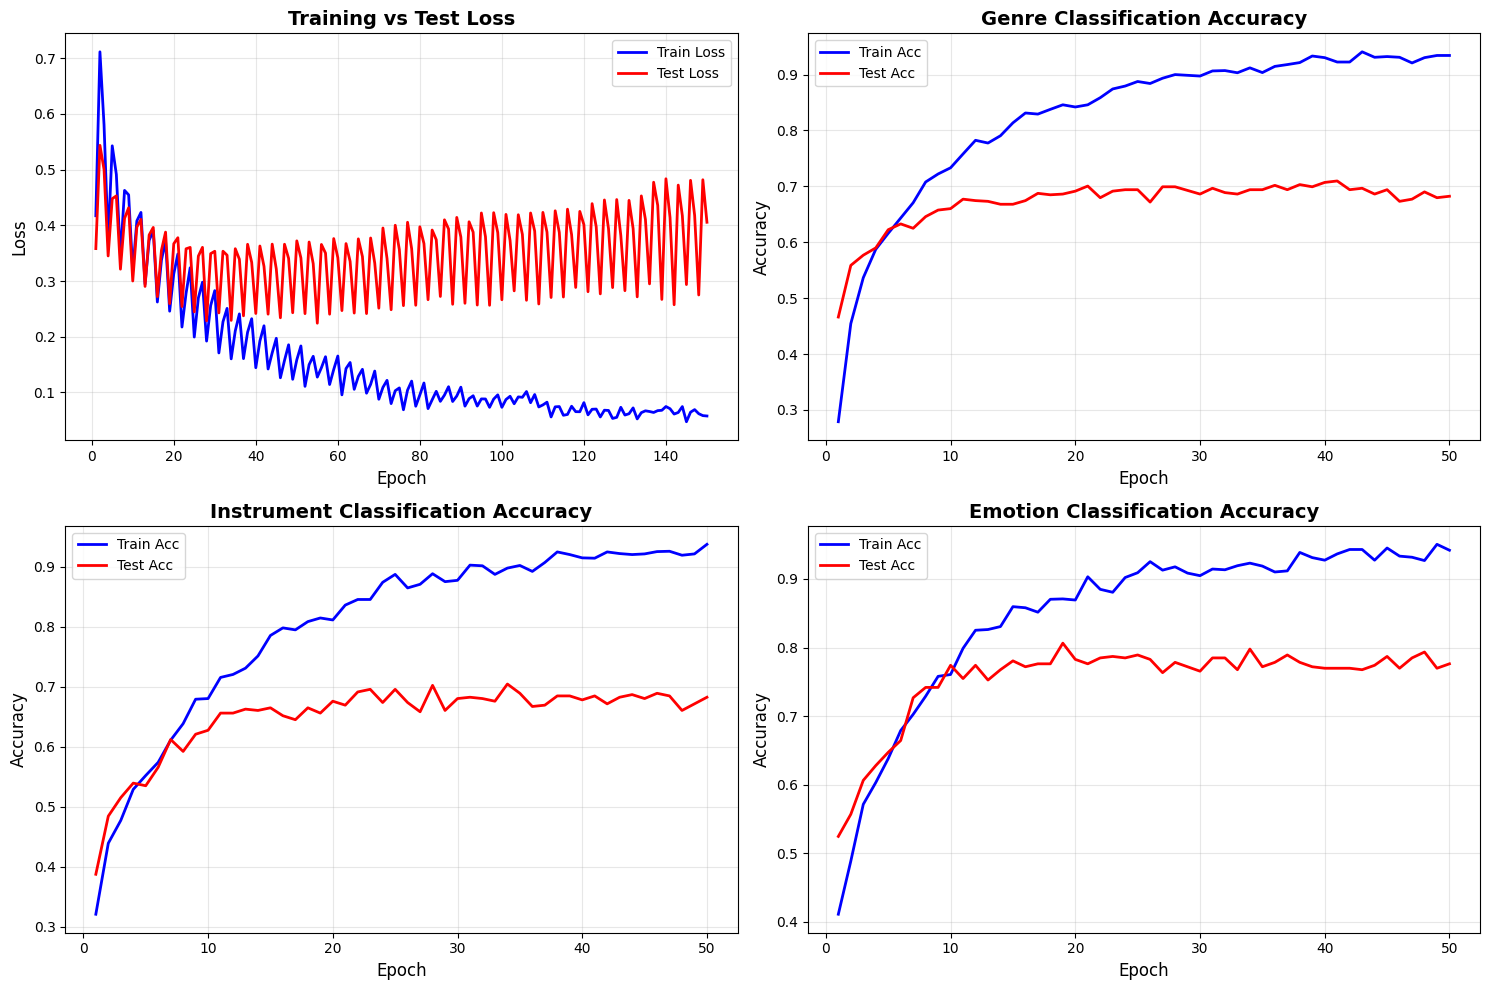

Plot saved to ../fig/combined_accuracy.png


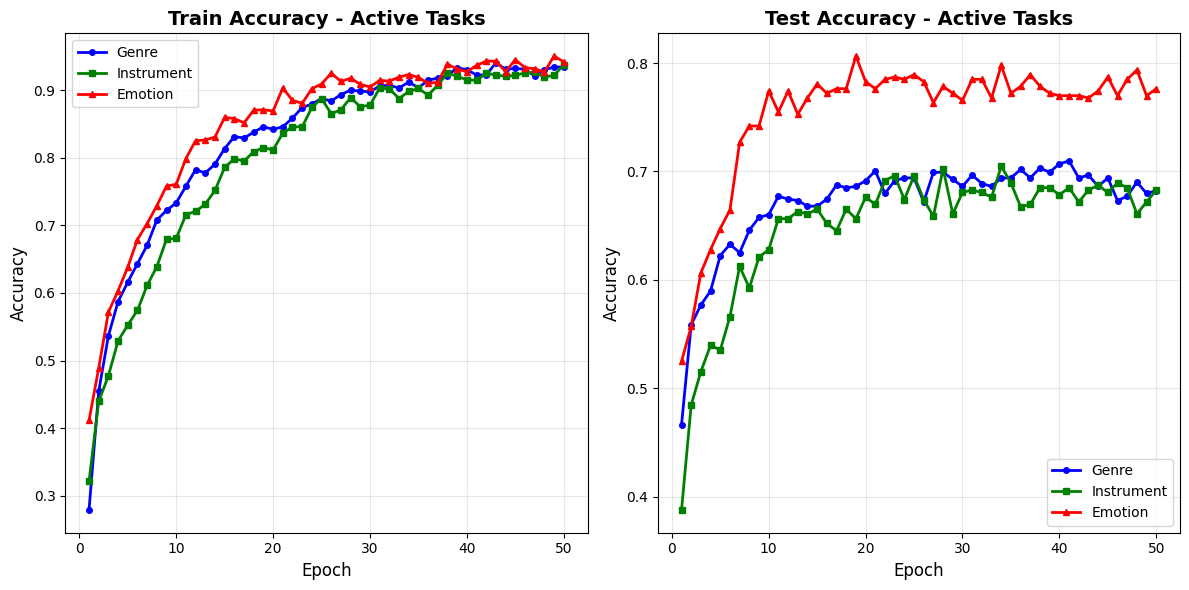

In [137]:
trainer.plot_metrics(save_path='../fig/training_metrics.png')
trainer.plot_combined_accuracy(save_path='../fig/combined_accuracy.png')

# Results 

### T-SNE Visualisation 

In [138]:
def tsn_visualisation(type_classif, labeled_csvs, unlabeled_csvs=None):

    if unlabeled_csvs is None:
        unlabeled_csvs = []

    embeddings_list = []
    tags_list = []
    source_mask = []
    # CSV AVEC LABELS
    for csv_path in labeled_csvs:
        data = pd.read_csv(csv_path)

        emb_cols = [c for c in data.columns if c.startswith("emb_")]
        embeddings = data[emb_cols].to_numpy()

        tags = data[type_classif].to_numpy()

        embeddings_list.append(embeddings)
        tags_list.append(tags)
        source_mask.extend([True] * len(embeddings))

    # CSV SANS LABELS
    for csv_path in unlabeled_csvs:
        data = pd.read_csv(csv_path)

        emb_cols = [c for c in data.columns if c.startswith("emb_")]
        embeddings = data[emb_cols].to_numpy()

        embeddings_list.append(embeddings)
        tags_list.append(np.array([None] * len(embeddings)))
        source_mask.extend([False] * len(embeddings))

    # CONCATÉNATION
    embeddings = np.vstack(embeddings_list)
    tags = np.concatenate(tags_list)
    source_mask = np.array(source_mask)

    print("✅ Total embeddings:", embeddings.shape)

    # t-SNE
    X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)

    # PLOT
    plt.figure(figsize=(10, 8))

    # Unlabeled
    unlabeled_idx = ~source_mask
    if np.any(unlabeled_idx):
        plt.scatter(
            X_2d[unlabeled_idx, 0],
            X_2d[unlabeled_idx, 1],
            color="lightgray",
            alpha=0.3,
            s=15,
            label="Projection only"
        )

    # Labeled
    labeled_idx = source_mask
    labeled_tags = tags[labeled_idx]
    unique_tags = np.unique(labeled_tags)

    cmap = plt.get_cmap("tab20")
    colors = {tag: cmap(i / len(unique_tags)) for i, tag in enumerate(unique_tags)}

    for tag in unique_tags:
        idx = (tags == tag) & labeled_idx
        plt.scatter(
            X_2d[idx, 0],
            X_2d[idx, 1],
            label=str(tag),
            color=colors[tag],
            alpha=0.8,
            s=20
        )

    plt.title(f"t-SNE Visualization of MuQ Embeddings ({type_classif})")
    plt.legend()
    plt.grid(True)

    plt.savefig(f"../fig/tsne_muQ_embeddings_{type_classif}.png", dpi=300)
    print("✅ t-SNE saved")

    return X_2d


## 1. Apply the model to the test dataSet and plot the result using T-SNE

In [139]:
def test_embeddings(data_loader, filenames_test, type_classif, label_encoder=None, file_name=None, device="cpu"):
    all_embeddings = []
    all_labels = []

    model.eval()
    with torch.no_grad():
        for batch in data_loader:
            inputs = batch['embedding'].to(device)
            labels = batch[type_classif].to(device)

            embeddings = model.get_embeddings(inputs)
            all_embeddings.append(embeddings)
            all_labels.append(labels)

    # Concat
    all_embeddings = torch.cat(all_embeddings, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    # CPU conversion
    embeddings_np = all_embeddings.cpu().numpy()
    labels_np = all_labels.cpu().numpy()

    # Label decoding
    if label_encoder is not None:
        labels_names = label_encoder.inverse_transform(labels_np)
    else:
        labels_names = labels_np

    # DataFrame
    df = pd.DataFrame(
        embeddings_np,
        columns=[f"emb_{i}" for i in range(embeddings_np.shape[1])]
    )
    df[type_classif] = labels_names
    df['filenames'] = filenames_test
    # Filename
    if file_name is None:
        file_name = f"{type_classif}_embeddings.csv"

    df.to_csv(file_name, index=False)
    print(f"✅ Embeddings saved to {file_name}")

    return file_name


In [140]:
def get_embedding_dim(csv_path, n_label_cols=1):
    """
    n_label_cols = nombre de colonnes label à la fin du CSV
    """
    data = pd.read_csv(csv_path)

    # Drop filename si présent
    if 'filename' in data.columns:
        data = data.drop(columns=['filename'])

    # Drop les colonnes label
    if n_label_cols > 0:
        data = data.iloc[:, :-n_label_cols]

    return data.shape[1]
print(get_embedding_dim("../embeddings/muq_embedding_jamendo_emotion.csv", n_label_cols=1))      # → 128
print(get_embedding_dim("../embeddings/muq_embedding_jamendo_instrument.csv", n_label_cols=2))
print(get_embedding_dim("../embeddings/muq_embedding_jamendo_genre.csv", n_label_cols=2))

1024
1023
1023


In [141]:
model.eval()

genre_csv_path = test_embeddings(genre_test_loader, genre_file_names_test, "genre", label_encoder=genre_data_dict["label_encoders"]["genre"], device="cuda")
instrument_csv_path = test_embeddings(instrument_test_loader, instrument_file_names_test, "instrument", label_encoder=instrument_data_dict['label_encoders']['instrument'], device="cuda")
emotion_csv_path = test_embeddings(emotion_test_loader, emotion_file_names_test, "emotion", label_encoder=emotion_data_dict['label_encoders']["emotion"], device="cuda")

✅ Embeddings saved to genre_embeddings.csv
✅ Embeddings saved to instrument_embeddings.csv
✅ Embeddings saved to emotion_embeddings.csv


## Genre :

✅ Total embeddings: (1687, 128)
✅ t-SNE saved


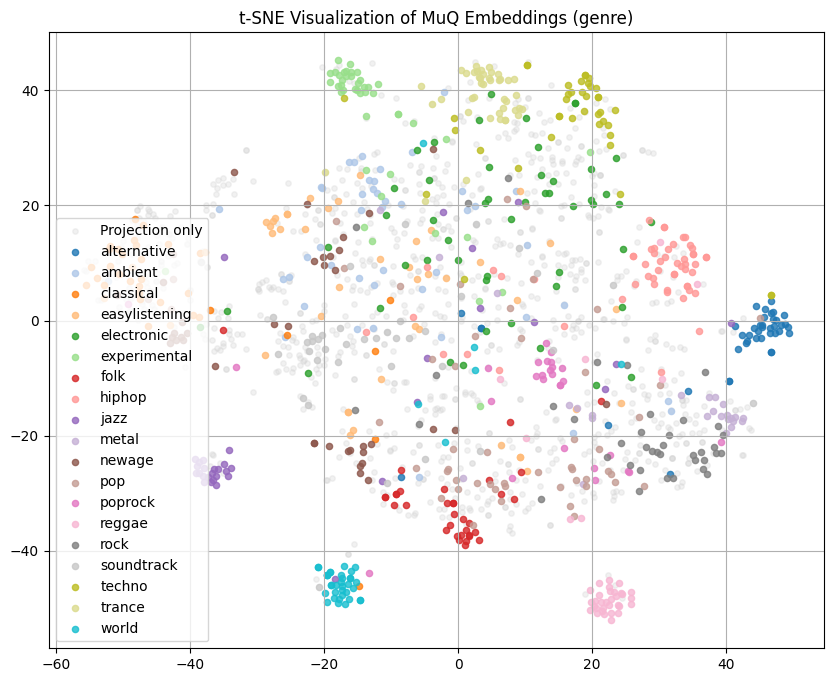

In [142]:
genre_tsne = tsn_visualisation("genre" , [genre_csv_path],unlabeled_csvs=[instrument_csv_path,emotion_csv_path])

## Instrument

✅ Total embeddings: (1687, 128)
✅ t-SNE saved


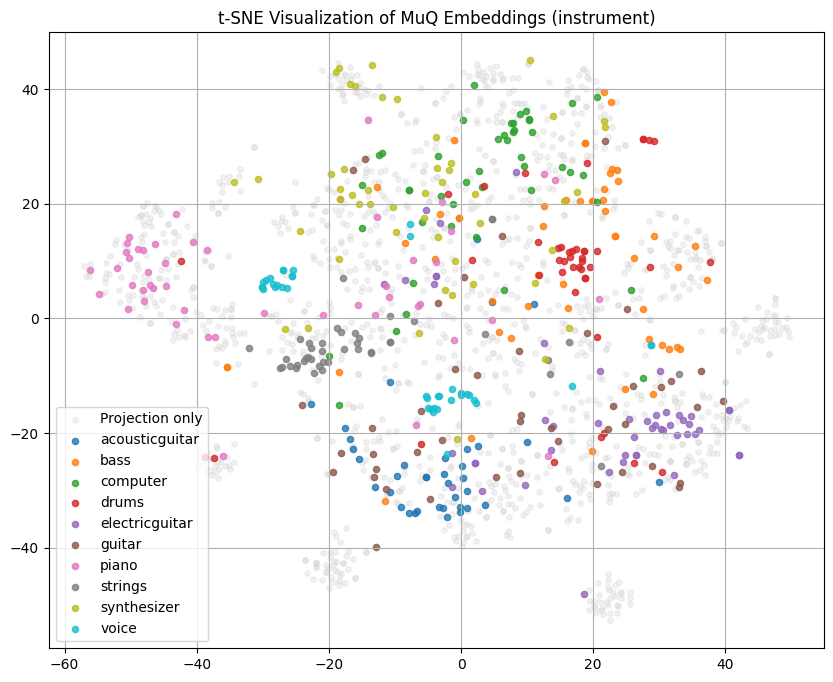

In [143]:
model.eval()
instrument_tsne = tsn_visualisation("instrument" , [instrument_csv_path],unlabeled_csvs=[genre_csv_path,emotion_csv_path])

## Emotion

✅ Total embeddings: (1687, 128)
✅ t-SNE saved


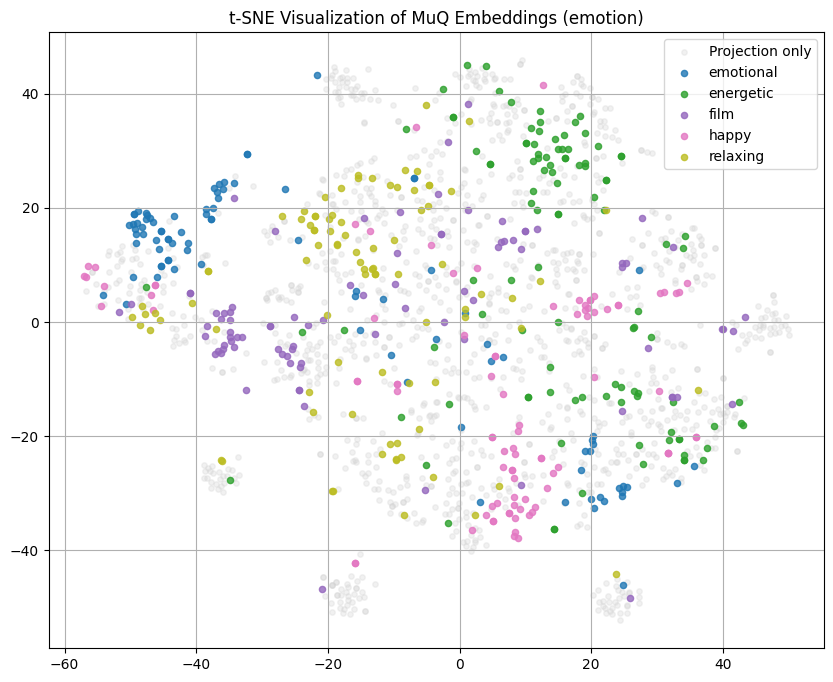

In [144]:
emotion_tsne= tsn_visualisation("emotion" , [emotion_csv_path],unlabeled_csvs=[instrument_csv_path,genre_csv_path])

# Playlist Generation

In [145]:
def load_embeddings_csv(csv_path, label_col, source_name):
    df = pd.read_csv(csv_path)

    # Colonnes embeddings
    emb_cols = [c for c in df.columns if c.startswith("emb_")]
    embeddings = df[emb_cols].to_numpy(dtype=np.float32)

    meta = pd.DataFrame({
        "label": df[label_col],
        "filename": df["filenames"],
        "source": source_name
    })

    return embeddings, meta


In [146]:
emb_g, meta_g = load_embeddings_csv(genre_csv_path, "genre", "GENRE")
emb_i, meta_i = load_embeddings_csv(instrument_csv_path, "instrument", "INSTRUMENT")
emb_e, meta_e = load_embeddings_csv(emotion_csv_path, "emotion", "EMOTION")

embeddings = np.vstack([emb_g, emb_i, emb_e])
meta_df = pd.concat([meta_g, meta_i, meta_e], ignore_index=True)

print("Embeddings shape:", embeddings.shape)
print(meta_df.head())


Embeddings shape: (1687, 128)
          label            filename source
0       poprock  04/1379104.low.mp3  GENRE
1         metal    11/76111.low.mp3  GENRE
2    electronic  46/1100246.low.mp3  GENRE
3  experimental  97/1397797.low.mp3  GENRE
4        hiphop   84/225784.low.mp3  GENRE


In [ ]:
def generate_and_analyze(
    embeddings,
    meta_df,
    playlist_size=8,
    n_playlists=3,
    div_start=0.0,
    div_end=1.0,
    random_state=42
):
    np.random.seed(random_state)

    print("t-SNE...")
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=random_state,
        init="pca"
    )
    coords = tsne.fit_transform(embeddings)

    print(" Nearest Neighbors...")
    nn_model = NearestNeighbors(n_neighbors=20)
    nn_model.fit(coords)

    def create_playlist(seed_idx, diversity):
        playlist = [seed_idx]
        available = set(range(len(coords))) - {seed_idx}

        while len(playlist) < playlist_size and available:
            last = playlist[-1]
            _, idxs = nn_model.kneighbors(
                coords[last].reshape(1, -1),
                n_neighbors=30
            )

            candidates = [i for i in idxs[0] if i in available]
            if not candidates:
                break

    
            if diversity == 0.0:
                sel = candidates[0]
            elif diversity == 1.0:
                sel = np.random.choice(candidates)
            else:
                sel = (
                    np.random.choice(candidates)
                    if np.random.rand() < diversity
                    else candidates[0]
                )

            playlist.append(sel)
            available.remove(sel)

        return playlist


    diversities = np.linspace(div_start, div_end, n_playlists)

    playlists = {}
    for i, div in enumerate(diversities):
        seed_idx = np.random.randint(len(coords))
        playlists[f"Random Walk {i+1} (div={div:.2f})"] = create_playlist(seed_idx, div)

    for name, indices in playlists.items():
        print(f"\n {name}")
        print(meta_df.loc[indices, ["source", "label", "filename"]])

    plt.figure(figsize=(14, 9))

    for lbl in meta_df["label"].unique():
        idx = meta_df["label"] == lbl
        plt.scatter(coords[idx, 0], coords[idx, 1], s=15, alpha=0.3)

    colors = ["black", "darkblue", "purple", "darkred", "darkgreen"]
    for i, (name, indices) in enumerate(playlists.items()):
        path = coords[indices]
        c = colors[i % len(colors)]

        plt.plot(path[:, 0], path[:, 1], c=c, linewidth=2, label=name)
        plt.scatter(
            path[:, 0],
            path[:, 1],
            c=c,
            s=60,
            edgecolors="white",
            zorder=10
        )

        plt.text(
            path[0, 0],
            path[0, 1],
            "START",
            fontsize=8,
            fontweight="bold",
            color=c
        )

    plt.legend(bbox_to_anchor=(1.05, 1))
    plt.title("Latent Space Random Walks – Progressive Diversity")
    plt.tight_layout()
    plt.show()

    return playlists


t-SNE...
 Nearest Neighbors...

🎵 Random Walk 1 (div=0.00)
          source      label            filename
1126  INSTRUMENT      piano   13/989713.low.mp3
571        GENRE  classical   37/873137.low.mp3
267        GENRE  classical   59/280159.low.mp3
919   INSTRUMENT      piano   41/271641.low.mp3
948   INSTRUMENT      piano   57/272957.low.mp3
279        GENRE  classical   37/431437.low.mp3
1249     EMOTION  emotional  81/1370481.low.mp3
68         GENRE  classical   86/259686.low.mp3
1140  INSTRUMENT      piano   15/259815.low.mp3
923   INSTRUMENT      piano  86/1345286.low.mp3

🎵 Random Walk 2 (div=0.12)
          source           label            filename
1459     EMOTION           happy  55/1357455.low.mp3
1643     EMOTION           happy  55/1357455.low.mp3
987   INSTRUMENT  acousticguitar  30/1146530.low.mp3
558        GENRE   easylistening  52/1373252.low.mp3
1623     EMOTION        relaxing  05/1066205.low.mp3
615        GENRE      soundtrack   85/213385.low.mp3
1055  INSTRUME

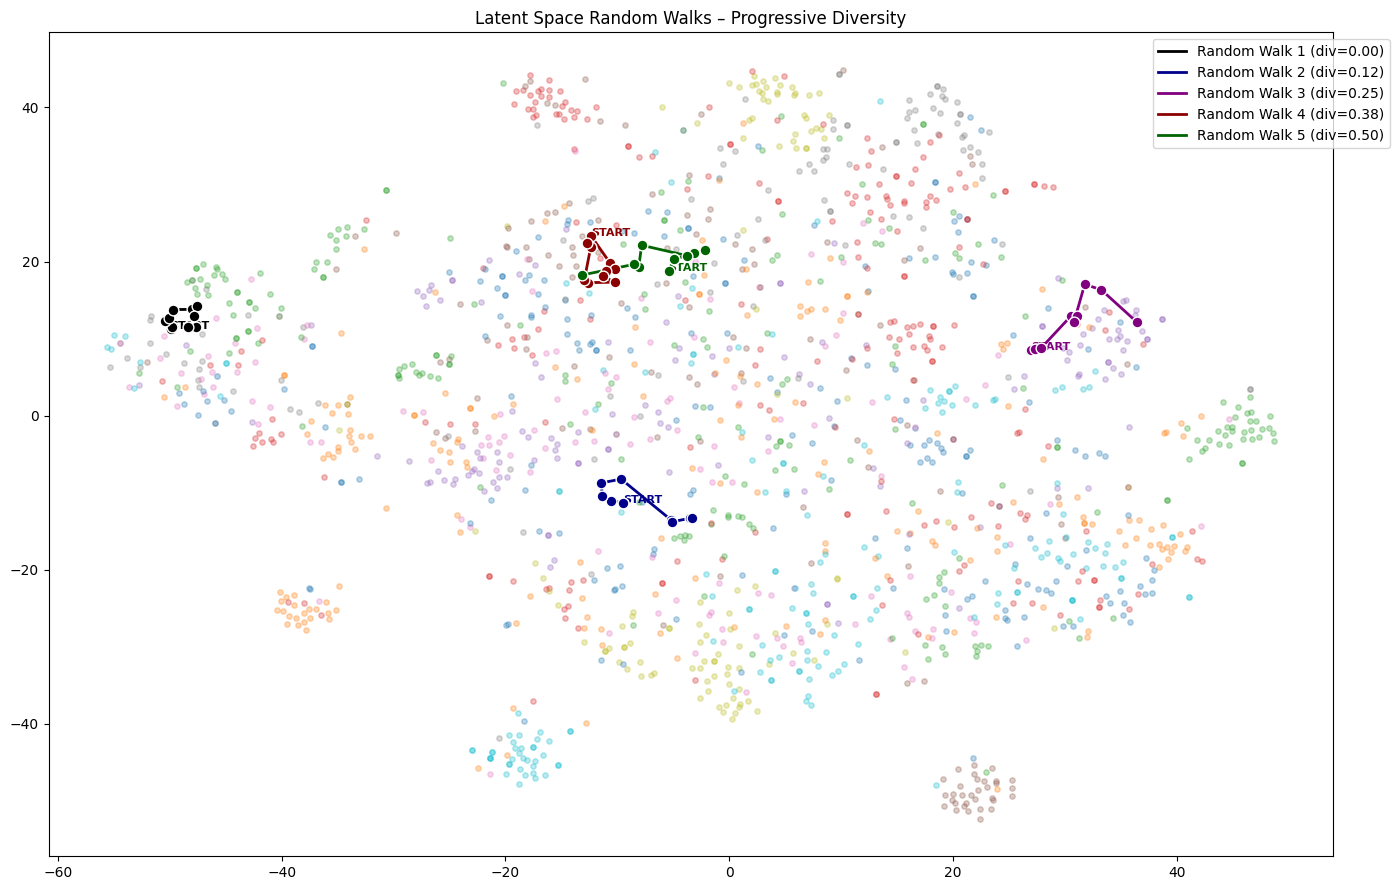

In [148]:
playlists = generate_and_analyze(
    embeddings,
    meta_df,
    playlist_size=10,
    n_playlists=5,
    div_start=0.0,
    div_end=0.5
)
